# Homework 8 - Beyond 1D visualizations

### Shivali Mate

In this homework, you will repeat the exploratory analysis from [class hands-on](../class) but with another dataset. And also provide your own observations of the data.

Feel free to choose your own dataset (like the one you are using for the final project), or to keep things simple, you can use the Cars dataset.

## Instructions

1. **Project Setup**:  
   - Set up your Python and Jupyter (or VSCode) environment.  
   - Clone or download the repository provided in class (refer to the class notes).

2. **Fill the cells**:
    - Fill in the cells with the code provided in the instructions.
    - You can use the provided code as a starting point and modify it as needed.
    - Make sure to run the code in each cell to see the output.
    - Also respond the markdown questions in the notebook where indicated.

3. **Documentation**:  
   - Comment your code and add markdown explanations for each part of your analysis.

4. **Submission**:  
   - Ensure your notebook is complete and all cells are executed without errors.
   - Save your notebook and export as either PDF or HTML. If the visualizations using altair are not being shown in the html, submit a separated version with altair html. Refer to: https://altair-viz.github.io/getting_started/starting.html#publishing-your-visualization (you can use the `chart.save('chart_file.html')` method).
   - Submit to Canvas.

Ok let's import the packages

In [ ]:
# For Jupyter notebooks, use 'widget' backend for interactivity
%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns

from pandas.plotting import parallel_coordinates
from mpl_toolkits.mplot3d import Axes3D
# make text editable in Illustrator
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# import altair
import altair as alt
alt.data_transformers.disable_max_rows()


DataTransformerRegistry.enable('default')

Now it is time to load a dataset. You can choose your own dataset or use the Cars dataset. If you want to use the Cars dataset, you can load it using the following code:


In [21]:
# Load ../Datasets/data_core.csv
df = pd.read_csv("data_core.csv") # adjust the path as needed
df.head()

,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26.0,52.0,38.0,Sandy,Maize,37,0,0,Urea
1,29.0,52.0,45.0,Loamy,Sugarcane,12,0,36,DAP
2,34.0,65.0,62.0,Black,Cotton,7,9,30,14-35-14
3,32.0,62.0,34.0,Red,Tobacco,22,0,20,28-28
4,28.0,54.0,46.0,Clayey,Paddy,35,0,0,Urea


### 2D Scatter plot
Choose two numeric variables from the dataset and plot a scatterplot using either matplotlib, seaborn, or altair. 
- Ensure to include appropriate labels and a title for the plot.

Try to encode an additional categorical variable (if available) in the scatterplot using color. For instance, for the car dataset, you can use Make or Fuel Type

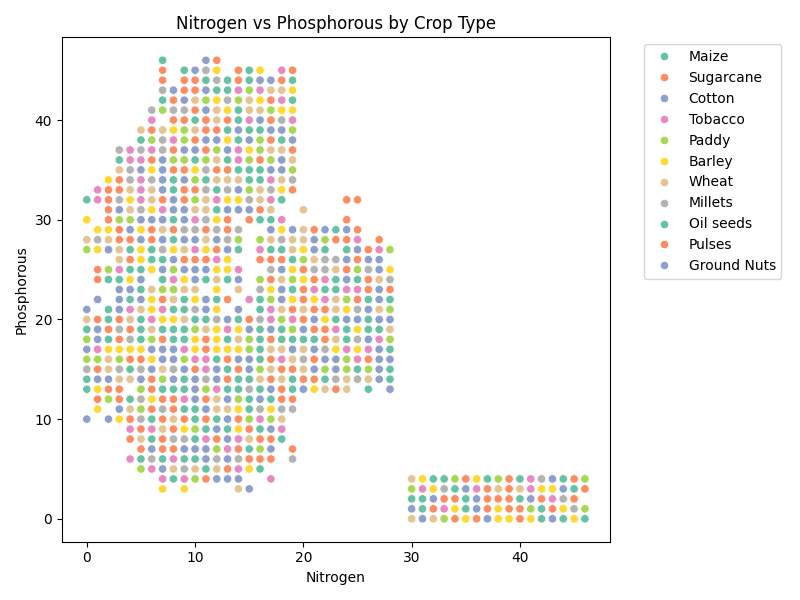

In [5]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Nitrogen', y='Phosphorous', hue='Crop Type', palette='Set2')
plt.title('Nitrogen vs Phosphorous by Crop Type')
plt.xlabel('Nitrogen')
plt.ylabel('Phosphorous')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 3D Scatter plot
Now choose three numeric variables from the dataset and plot a 3D scatterplot. You can use matplotlib's `mpl_toolkits.mplot3d` or any other library that supports 3D plotting.

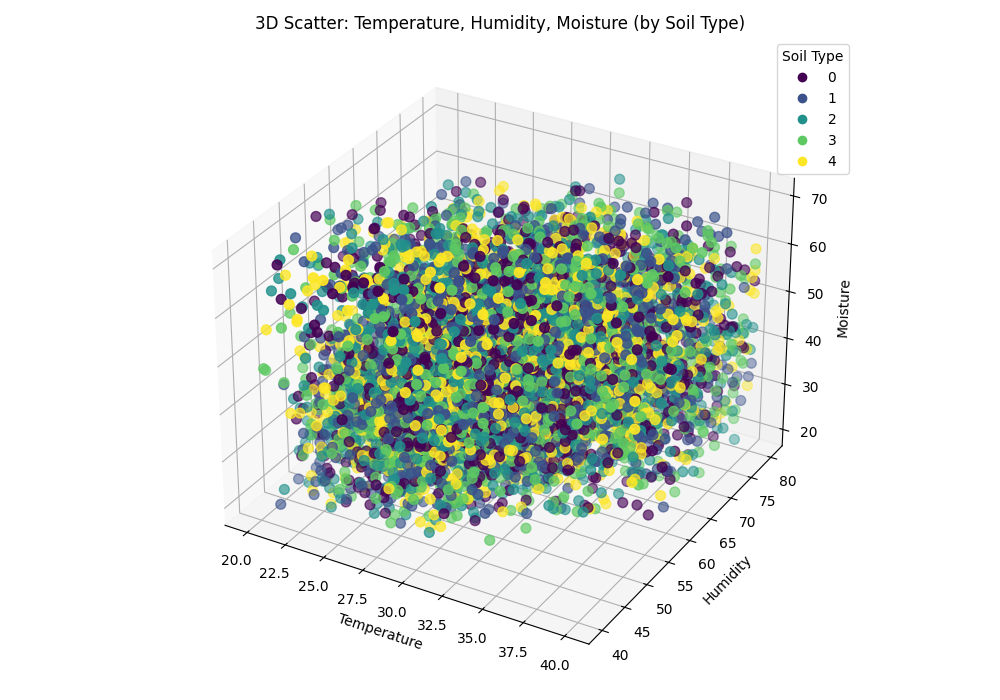

In [ ]:
# YOUR CODE HERE
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    df['Temparature'], df['Humidity'], df['Moisture'],
    c=pd.factorize(df['Soil Type'])[0],
    cmap='viridis', s=50
)

ax.set_xlabel('Temperature')
ax.set_ylabel('Humidity')
ax.set_zlabel('Moisture')
ax.set_title('3D Scatter: Temperature, Humidity, Moisture (by Soil Type)')
plt.legend(*scatter.legend_elements(), title="Soil Type", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()


### Find the numeric variables in the dataset
Now we will find all the numeric variables in the dataset. This will help us choose the variables for the further analysis.

In [ ]:
# list of numeric features (get from data)
numeric_features = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
numeric_features

['Temparature', 'Humidity', 'Moisture', 'Nitrogen', 'Potassium', 'Phosphorous']

### Correlation Matrix
For your selection of numeric variables, plot the correlation matrix using seaborn's `heatmap` or any other visualization library of your choice.

First Pearson, then Spearman correlation. Do you see any differences?

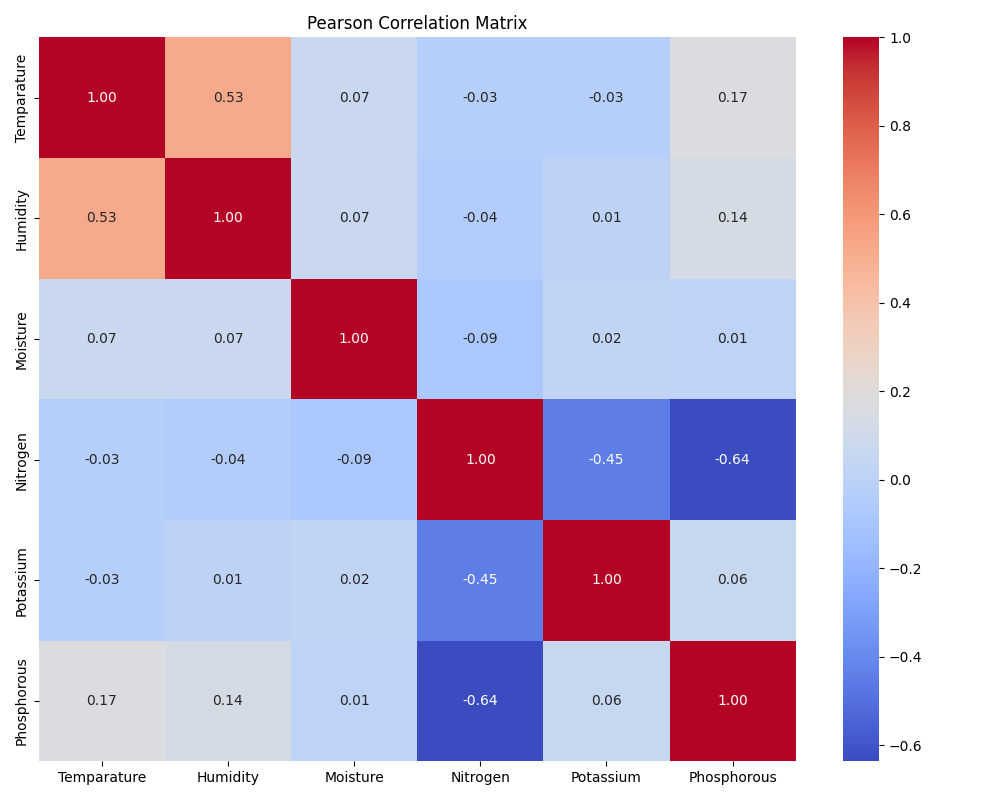

In [10]:
# Pearson correlation matrix
# YOUR CODE HERE
num_df = df[numeric_features].dropna()

plt.figure(figsize=(10, 8))
sns.heatmap(num_df.corr(method='pearson'), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Pearson Correlation Matrix')
plt.tight_layout()
plt.show()

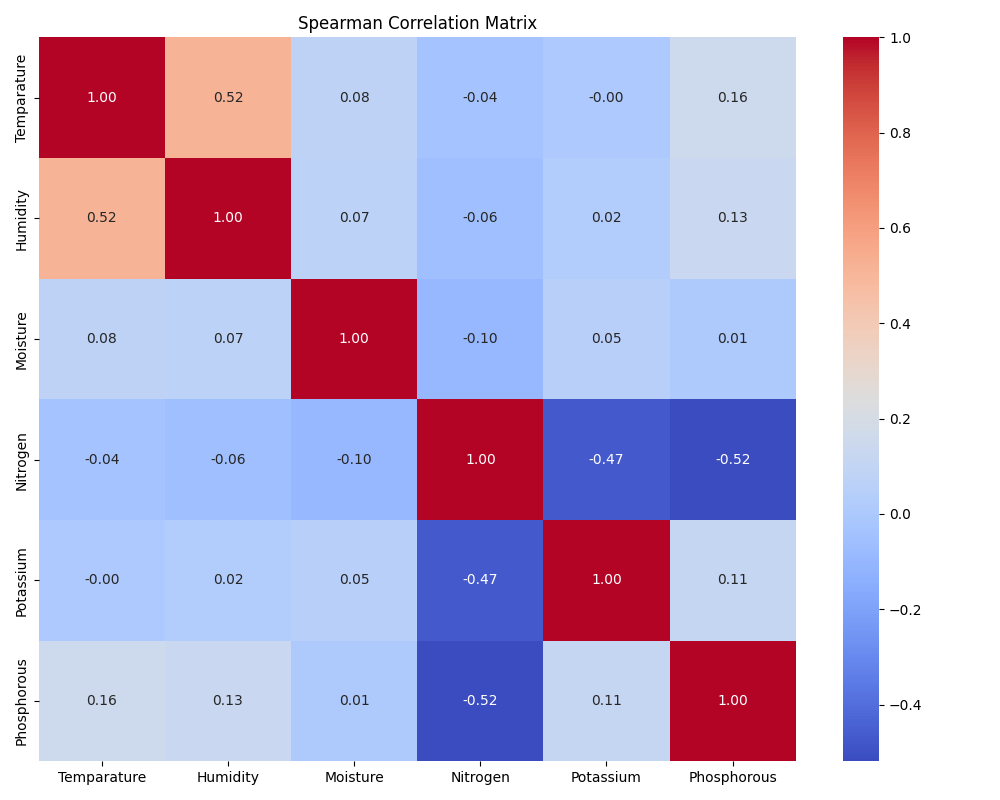

In [11]:
# Spearman correlation matrix
# YOUR CODE HERE
plt.figure(figsize=(10, 8))
sns.heatmap(num_df.corr(method='spearman'), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Spearman Correlation Matrix')
plt.tight_layout()
plt.show()

### Scatterplot matrix
To visualize the relationships between all numeric variables, create a scatterplot matrix (also known as a pair plot). You can use seaborn's `pairplot`.

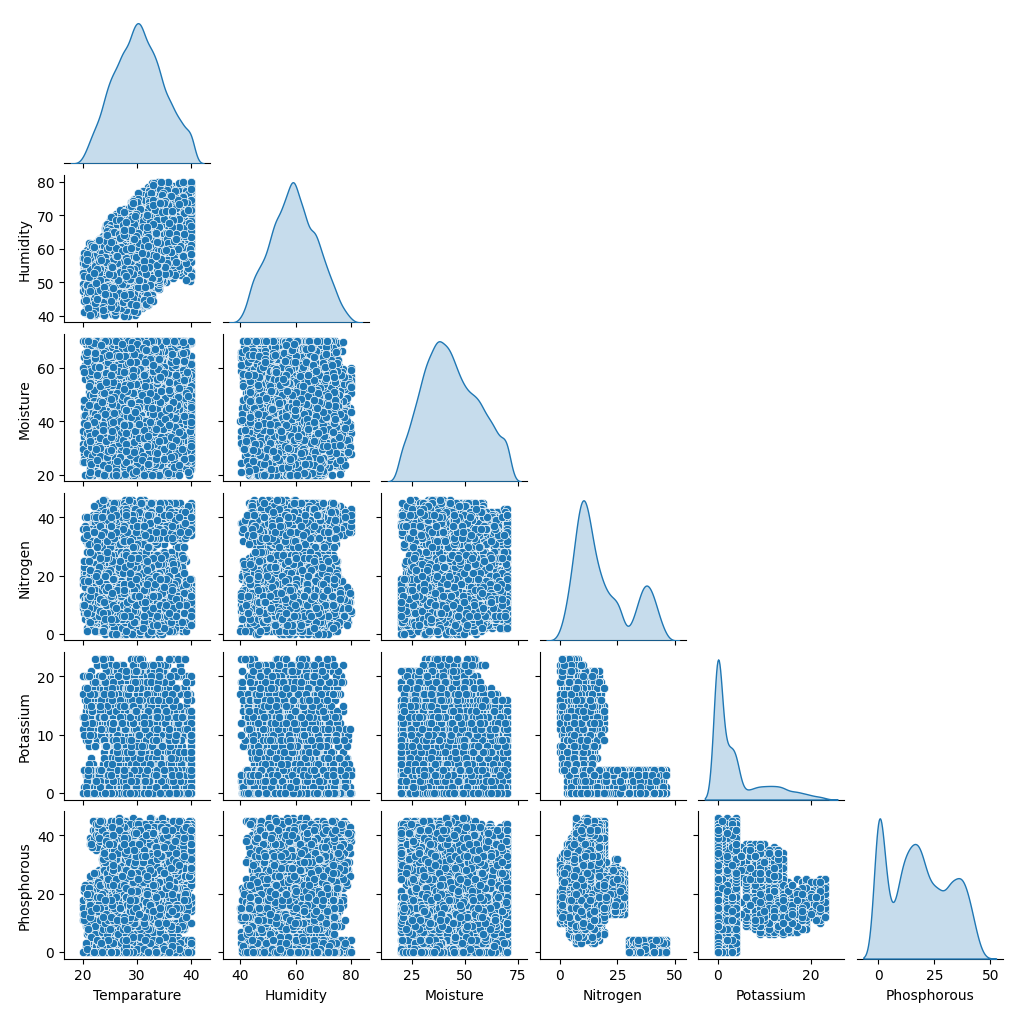

In [18]:
# YOUR CODE HERE
sns.pairplot(num_df, diag_kind='kde', corner=True, height=1.7, aspect=1)
plt.suptitle('Scatterplot Matrix of Numeric Variables', y=1.02)
plt.show()


### Parallel Coordinates Plot
Another way to visualize multi-dimensional data is by using a parallel coordinates plot. You can either use pandas or altair for this.

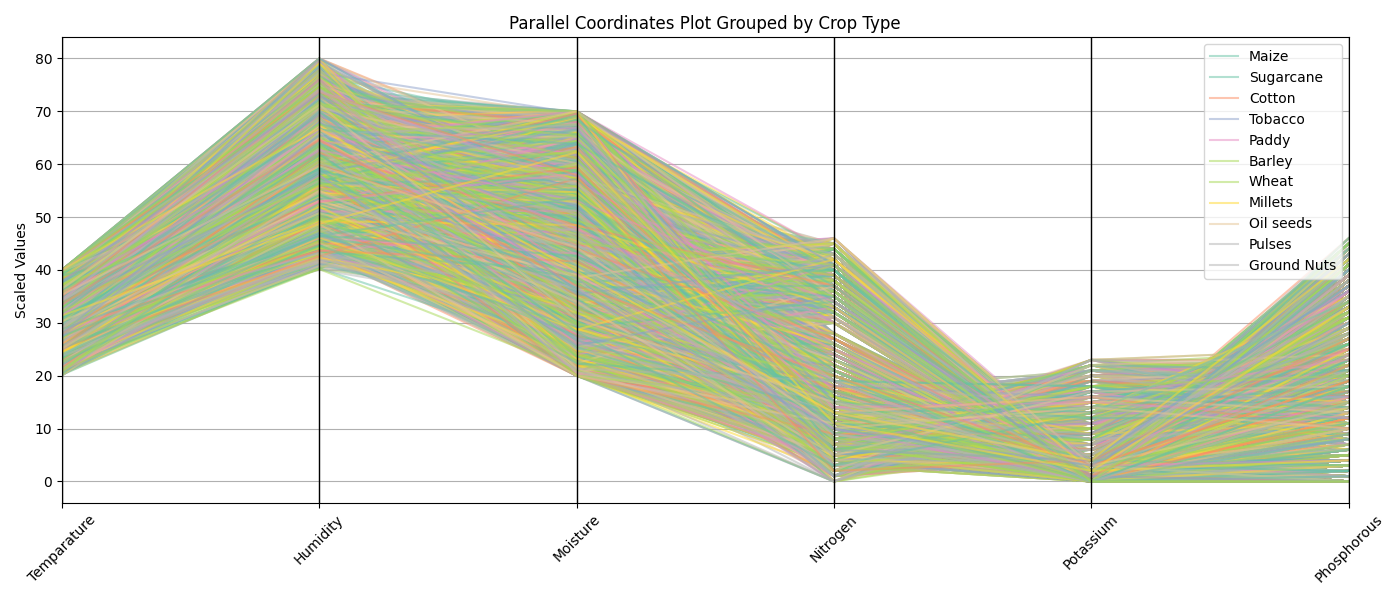

In [ ]:
# YOUR CODE HERE
cols_to_plot = ['Temparature', 'Humidity', 'Moisture', 'Nitrogen', 'Potassium', 'Phosphorous', 'Crop Type']

plt.figure(figsize=(14, 6))
parallel_coordinates(df[cols_to_plot], class_column='Crop Type', colormap=plt.cm.Set2, alpha=0.5)
plt.title("Parallel Coordinates Plot Grouped by Crop Type")
plt.ylabel("Scaled Values")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


### Discussion
Write a brief discussion on your observations from the visualizations above. Consider the following questions:
 - Did you gain any insights from the scatter plots (2D and 3D)?
 - Any interesting correlations you found in the correlation matrix?
 - Do you think the scatterplot matrix was helpful in understanding the relationships between variables? Was it too crowded or too sparse?
 - What about the parallel coordinates plot? Did it help in understanding the multi-dimensional relationships? Or was it too messy?



 `YOUR DISCUSSION HERE`

### Did you gain any insights from the scatter plots (2D and 3D)?

- the 2D plot revealed distinct groupings of crops based on Nitrogen and Phosphorous levels, though a dense cluster at high Nitrogen and low Phosphorous may indicate data issues.
- The 3D plot showed overlapping but slightly distinct distributions of soil types across temperature, humidity, and moisture ranges.
- Both plots helped uncover patterns in crop and soil characteristics, though some noise or overlap limits deeper interpretation.

### Any interesting correlations you found in the correlation matrix?
- Nitrogen is negatively correlated with both Phosphorous and Potassium, indicating a possible nutrient trade-off.
- Temperature and Humidity show a moderate positive correlation, reflecting environmental linkage.
- To summarize Nitrogen stands out for its inverse relationship with other key nutrients, while temperature aligns moderately with humidity.

### Do you think the scatterplot matrix was helpful in understanding the relationships between variables? Was it too crowded or too sparse?
- The scatterplot matrix was helpful in spotting broad trends, like the dense clustering and skewed distributions of Nitrogen and Potassium.
- However, it felt a bit crowded, especially with overlapping points, making it hard to interpret fine-grained relationships.
- To summerize useful for an overview, but simplifying variables or sampling the data could improve clarity.

### What about the parallel coordinates plot? Did it help in understanding the multi-dimensional relationships? Or was it too messy?
- The parallel coordinates plot captures multi-dimensional trends across crop types and shows some variation in nutrient needs.
- However, it becomes visually messy due to overlapping lines and many categories, making it hard to isolate specific patterns.
- To summarize it gives a broad sense of variability, but filtering or focusing on fewer crop types would improve readability.